In [1]:
#08 RESULTS: ΔHfus BASELINE MODEL
#CLEANED VERSION. EVERYTHING IS READ FROM THE FILES WRITTEN BY run_baseline.py (NOTHING IS RETRAINED HERE).
#RUN THE CELLS TOP TO BOTTOM, IN THE FOLDER THAT CONTAINS THE BASELINE CSV FILES.
import numpy as np                                                         #LIBRARY FOR NUMERICAL OPERATIONS
import pandas as pd                                                        #LIBRARY FOR DATA TABLES
import matplotlib.pyplot as plt                                            #LIBRARY FOR PLOTTING
from pathlib import Path                                                   #LIBRARY FOR FILE PATHS
from scipy import stats                                                    #LIBRARY FOR CORRELATIONS
from rdkit import Chem, RDLogger                                           #LIBRARY FOR FUNCTIONAL GROUP CLASSIFICATION
from matplotlib.patches import Patch                                       #LEGEND ENTRIES FOR THE SHADED BANDS
RDLogger.DisableLog("rdApp.*")                                             #SILENCES RDKIT WARNINGS

DS = "dHfus"                                                              #DATASET: "dHfus" OR "Tm"
CFG = {
    "dHfus": dict(name="ΔHfus", unit="kcal/mol", n_test=450,  bands=(1.5, 3.0),  edges=[0, 1.5, 3, 5, 10, np.inf],  cum=[1.5, 3, 5],   near_zero=0.5),
    "Tm":    dict(name="Tm",    unit="K",        n_test=1000, bands=(25.0, 50.0), edges=[0, 25, 50, 100, np.inf],    cum=[25, 50, 100], near_zero=50.0),
}[DS]                                                                      #BANDS MATCH THE PARITY BANDS USED IN SECTION 5.8
NAME, UNIT = CFG["name"], CFG["unit"]
print("DATASET:", DS, "| EXPECTED TEST SET SIZE:", CFG["n_test"])

DATASET: dHfus | EXPECTED TEST SET SIZE: 450


In [2]:
#LOAD THE SEED 0 TEST PREDICTIONS AND CHECK THEY ARE THE CURRENT ONES
pred = pd.read_csv(f"{DS}_baseline_predictions.csv")                       #SEED 0 TEST PREDICTIONS
pred["residual"] = pred["y_pred"] - pred["y_true"]                         #PREDICTED MINUS TRUE
pred["abs_error"] = pred["residual"].abs()                                 #ABSOLUTE ERROR, RECOMPUTED SO OLD AND NEW FILE FORMATS BOTH WORK
pred["rel_error_pct"] = 100 * pred["abs_error"] / pred["y_true"].abs()     #RELATIVE ERROR IN PERCENT
seeds = pd.read_csv(f"baseline_seeds_{DS}.csv")                            #10-SEED RESULTS
s0 = seeds[seeds["seed"] == 0].iloc[0]                                     #SEED 0 ROW, TO CROSS-CHECK THE PREDICTIONS FILE

mae = pred["abs_error"].mean()
rmse = np.sqrt((pred["abs_error"] ** 2).mean())
print(f"PREDICTIONS FILE: {len(pred)} MOLECULES | MAE = {mae:.4f} | RMSE = {rmse:.4f}")
print(f"SEED 0 IN baseline_seeds_{DS}.csv: MAE = {s0['test_mae']:.4f} | RMSE = {s0['test_rmse']:.4f}")
ok_n = len(pred) == CFG["n_test"]
ok_mae = np.isclose(mae, s0["test_mae"], rtol=2e-3)
if not (ok_n and ok_mae):                                                  #STOPS HERE IF THE PREDICTIONS FILE IS OLD (WRONG SIZE OR WRONG ERROR)
    raise RuntimeError(f"STALE PREDICTIONS FILE: SIZE OK = {ok_n}, MAE MATCHES SEED 0 = {ok_mae}. RERUN run_baseline.py (OR RESTORE THE NEW FILE) BEFORE CONTINUING")
print("CHECK PASSED: THE PREDICTIONS FILE IS THE CURRENT SEED 0 BASELINE")

PREDICTIONS FILE: 450 MOLECULES | MAE = 1.7085 | RMSE = 2.7878
SEED 0 IN baseline_seeds_dHfus.csv: MAE = 1.7085 | RMSE = 2.7878
CHECK PASSED: THE PREDICTIONS FILE IS THE CURRENT SEED 0 BASELINE


In [3]:
#10-SEED SUMMARY OF THE BASELINE (THE NUMBERS QUOTED IN THE REPORT)
cols = ["test_mae", "test_rmse", "epochs"]
summary = seeds[cols].agg(["mean", "std", "median", "min", "max"]).T.round(3)   #MEAN AND SPREAD OVER SEEDS
print(summary)
print(seeds[["seed"] + cols].round(3).to_string(index=False))              #ONE ROW PER SEED
print("RMSE/MAE RATIO, MEAN OVER SEEDS:", round((seeds["test_rmse"] / seeds["test_mae"]).mean(), 2))   #LARGE RATIO = A FEW LARGE ERRORS
print("SEEDS THAT REACHED THE 50 EPOCH LIMIT:", int((seeds["epochs"] >= 50).sum()), "OF", len(seeds))
summary.to_csv(f"{DS}_baseline_summary.csv")

             mean    std  median     min     max
test_mae    1.816  0.139   1.856   1.491   1.968
test_rmse   3.359  1.037   2.965   2.087   4.927
epochs     37.800  8.829  34.500  26.000  50.000
 seed  test_mae  test_rmse  epochs
    0     1.708      2.788      32
    1     1.736      2.494      34
    2     1.836      3.021      29
    3     1.891      4.558      26
    4     1.491      2.087      35
    5     1.927      4.927      48
    6     1.835      2.932      32
    7     1.875      2.874      44
    8     1.894      2.998      50
    9     1.968      4.917      48
RMSE/MAE RATIO, MEAN OVER SEEDS: 1.83
SEEDS THAT REACHED THE 50 EPOCH LIMIT: 1 OF 10


LOSS CURVE EPOCHS: 33 | SEED 0 TRAINED FOR 32 EPOCHS (THESE SHOULD AGREE IF THE CURVE IS SEED 0)


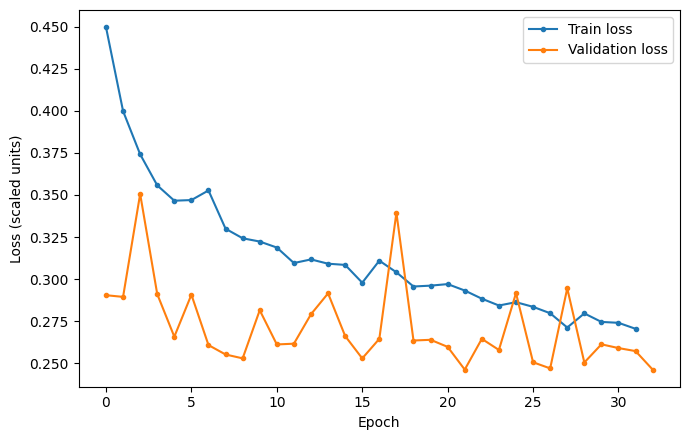

        Split   MAE  RMSE    N
        Train 1.695 4.096 3601
Test (seed 0) 1.708 2.788  450
TEST MAE IS 0.8% HIGHER THAN TRAIN MAE


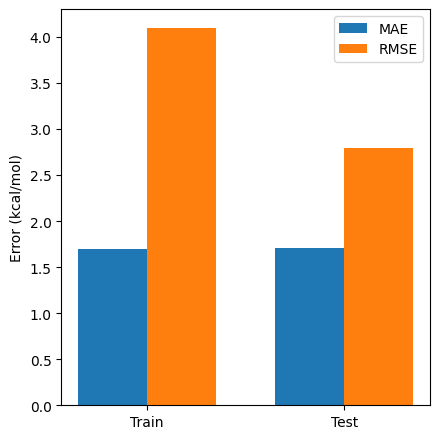

In [4]:
#TRAINING DIAGNOSTICS: LOSS CURVES AND TRAIN VS TEST ERROR (OPTIONAL FILES, SKIPPED IF NOT FOUND)
LOSS_FILE = Path(f"{DS}_baseline_loss_curve.csv")
if LOSS_FILE.exists():
    lc = pd.read_csv(LOSS_FILE)
    em = lc.groupby("epoch")[["train_loss_epoch", "val_loss"]].mean()      #MEAN PER EPOCH
    print("LOSS CURVE EPOCHS:", int(em.index.max()) + 1, "| SEED 0 TRAINED FOR", int(s0["epochs"]), "EPOCHS (THESE SHOULD AGREE IF THE CURVE IS SEED 0)")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(em.index, em["train_loss_epoch"], label="Train loss", marker="o", markersize=3)
    ax.plot(em.index, em["val_loss"], label="Validation loss", marker="o", markersize=3)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss (scaled units)"); ax.legend()
    plt.tight_layout(); plt.savefig(f"plots_{DS}_loss_curves.png", dpi=150); plt.show()
else:
    print("SKIPPED LOSS CURVE: FILE NOT FOUND:", LOSS_FILE)

TRAIN_FILE = Path(f"{DS}_baseline_train_predictions.csv")
if TRAIN_FILE.exists():
    tr = pd.read_csv(TRAIN_FILE)
    tr_abs = (tr["y_pred"] - tr["y_true"]).abs()                           #TRAINING SET ABSOLUTE ERRORS
    tr_mae, tr_rmse = tr_abs.mean(), np.sqrt((tr_abs ** 2).mean())
    cmp_ = pd.DataFrame({"Split": ["Train", "Test (seed 0)"], "MAE": [tr_mae, mae], "RMSE": [tr_rmse, rmse], "N": [len(tr), len(pred)]})
    print(cmp_.round(3).to_string(index=False))
    print(f"TEST MAE IS {(mae - tr_mae) / tr_mae * 100:.1f}% HIGHER THAN TRAIN MAE")
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    x = np.arange(2)
    ax.bar(x - 0.175, cmp_["MAE"], 0.35, label="MAE"); ax.bar(x + 0.175, cmp_["RMSE"], 0.35, label="RMSE")
    ax.set_xticks(x); ax.set_xticklabels(["Train", "Test"]); ax.set_ylabel(f"Error ({UNIT})"); ax.legend()
    plt.tight_layout(); plt.savefig(f"plots_{DS}_train_vs_test.png", dpi=150); plt.show()
else:
    print("SKIPPED TRAIN VS TEST: FILE NOT FOUND:", TRAIN_FILE)

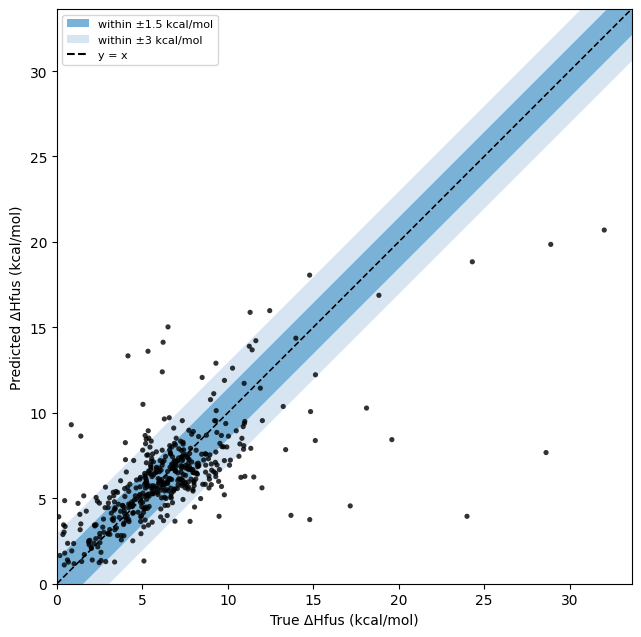

WITHIN ±1.5 kcal/mol: 61.6%
WITHIN ±3 kcal/mol: 86.7%

FIVE LARGEST ERRORS:
                                       smiles  y_true  y_pred  residual
COCCc1ccc(OCC(O)CNC(C)C)cc1.COCCc1ccc(OCC(O)C   28.62    7.67    -20.95
O=[N+]([O-])N1CCC([N+](=O)[O-])([N+](=O)[O-])   24.00    3.95    -20.05
[CH2]C(C)(C)c1ccccc1.[CH2]C(C)(C)c1ccccc1.[CH   17.16    4.55    -12.61
CCCCCCCCCCCCCCCCCCCOC1=CC(=O)C(OCCCCCCCCCCCCC   32.03   20.69    -11.33
COC1=C(OC)C(=O)C(CC=C(C)CCC=C(C)CCC=C(C)CCC=C   19.60    8.43    -11.17


In [5]:
#PARITY PLOT WITH ERROR BANDS, AND THE SHARE OF MOLECULES INSIDE EACH BAND
b1, b2 = CFG["bands"]
lim = max(pred["y_true"].max(), pred["y_pred"].max()) * 1.05
xl = np.linspace(0, lim, 200)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for lo, hi, c in [(0, b1, "#4292c6"), (b1, b2, "#c6dbef")]:                #DARK = WITHIN b1, LIGHT = BETWEEN b1 AND b2
    ax.fill_between(xl, xl + lo, xl + hi, color=c, alpha=0.7, linewidth=0)
    ax.fill_between(xl, np.maximum(xl - hi, 0), np.maximum(xl - lo, 0), color=c, alpha=0.7, linewidth=0)
ax.plot(xl, xl, "k--", linewidth=1.2, zorder=5)
ax.scatter(pred["y_true"], pred["y_pred"], color="black", s=14, alpha=0.8, zorder=6, edgecolor="none")
ax.legend(handles=[Patch(facecolor="#4292c6", alpha=0.7, label=f"within ±{b1:g} {UNIT}"),
                   Patch(facecolor="#c6dbef", alpha=0.7, label=f"within ±{b2:g} {UNIT}"),
                   plt.Line2D([0], [0], color="black", linestyle="--", label="y = x")], loc="upper left", fontsize=8)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(f"True {NAME} ({UNIT})"); ax.set_ylabel(f"Predicted {NAME} ({UNIT})")
plt.tight_layout(); plt.savefig(f"plots_{DS}_parity_bands.png", dpi=150); plt.show()

for b in (b1, b2):
    print(f"WITHIN ±{b:g} {UNIT}: {100 * (pred['abs_error'] <= b).mean():.1f}%")
print("\nFIVE LARGEST ERRORS:")
big = pred.nlargest(5, "abs_error")[["smiles", "y_true", "y_pred", "residual"]].copy()
big["smiles"] = big["smiles"].str.slice(0, 45)
print(big.round(2).to_string(index=False))                                 #NEGATIVE RESIDUAL = UNDERPREDICTION

Band (kcal/mol)  Count  Percentage  Cumulative %
          0-1.5    277        61.6          61.6
          1.5-3    113        25.1          86.7
            3-5     37         8.2          94.9
           5-10     17         3.8          98.7
            >10      6         1.3         100.0

EXCLUDED FROM RELATIVE ERROR: 9 MOLECULES WITH |TRUE VALUE| < 0.5 kcal/mol
ABSOLUTE ERROR: MEAN 1.708 | MEDIAN 1.154 | 90TH PCT 3.361 | 95TH PCT 5.048 | MAX 20.946
RELATIVE ERROR: MEAN 30.8% | MEDIAN 18.5%


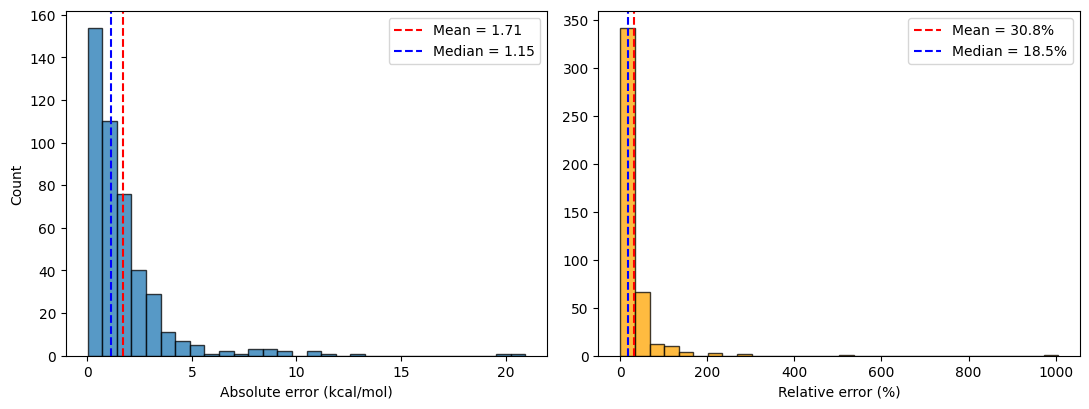

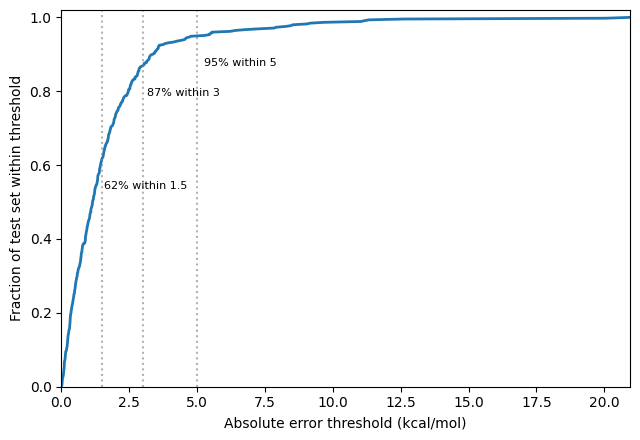

In [6]:
#ERROR BAND TABLE, CUMULATIVE ERRORS AND ERROR STATISTICS
edges = CFG["edges"]
labels = [f"{lo:g}-{hi:g}" if np.isfinite(hi) else f">{lo:g}" for lo, hi in zip(edges[:-1], edges[1:])]
pred["error_band"] = pd.cut(pred["abs_error"], bins=edges, labels=labels, right=True, include_lowest=True)
counts = pred["error_band"].value_counts().reindex(labels)
band_tab = pd.DataFrame({f"Band ({UNIT})": labels, "Count": counts.values,
                         "Percentage": (counts / len(pred) * 100).round(1).values,
                         "Cumulative %": (counts.cumsum() / len(pred) * 100).round(1).values})
print(band_tab.to_string(index=False))
band_tab.to_csv(f"{DS}_baseline_error_bands.csv", index=False)

nz = pred["y_true"].abs() < CFG["near_zero"]                               #NEAR-ZERO TRUE VALUES GIVE MEANINGLESS RELATIVE ERRORS
rel = pred.loc[~nz, "rel_error_pct"]
print(f"\nEXCLUDED FROM RELATIVE ERROR: {int(nz.sum())} MOLECULES WITH |TRUE VALUE| < {CFG['near_zero']:g} {UNIT}")
print(f"ABSOLUTE ERROR: MEAN {mae:.3f} | MEDIAN {pred['abs_error'].median():.3f} | 90TH PCT {pred['abs_error'].quantile(0.9):.3f} | 95TH PCT {pred['abs_error'].quantile(0.95):.3f} | MAX {pred['abs_error'].max():.3f}")
print(f"RELATIVE ERROR: MEAN {rel.mean():.1f}% | MEDIAN {rel.median():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(pred["abs_error"], bins=30, edgecolor="black", alpha=0.75)
axes[0].axvline(mae, color="red", linestyle="--", label=f"Mean = {mae:.2f}")
axes[0].axvline(pred["abs_error"].median(), color="blue", linestyle="--", label=f"Median = {pred['abs_error'].median():.2f}")
axes[0].set_xlabel(f"Absolute error ({UNIT})"); axes[0].set_ylabel("Count"); axes[0].legend()
axes[1].hist(rel, bins=30, edgecolor="black", alpha=0.75, color="orange")
axes[1].axvline(rel.mean(), color="red", linestyle="--", label=f"Mean = {rel.mean():.1f}%")
axes[1].axvline(rel.median(), color="blue", linestyle="--", label=f"Median = {rel.median():.1f}%")
axes[1].set_xlabel("Relative error (%)"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"plots_{DS}_error_distributions.png", dpi=150); plt.show()

xs = np.sort(pred["abs_error"].values)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(xs, np.arange(1, len(xs) + 1) / len(xs), linewidth=2)
for t in CFG["cum"]:
    f = (pred["abs_error"] <= t).mean()
    ax.axvline(t, color="gray", linestyle=":", alpha=0.6)
    ax.annotate(f"{f:.0%} within {t:g}", xy=(t, f), xytext=(t * 1.05, f - 0.08), fontsize=8)
ax.set_xlabel(f"Absolute error threshold ({UNIT})"); ax.set_ylabel("Fraction of test set within threshold")
ax.set_xlim(0, xs.max()); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(f"plots_{DS}_cumulative_error.png", dpi=150); plt.show()

RESIDUAL TREND SLOPE: -0.498 | CORRELATION BETWEEN TRUE VALUE AND RESIDUAL: -0.672 | MEAN RESIDUAL: -0.283 | SD: 2.776
              count   mean
y_true                    
Low third       150  0.853
Middle third    150  0.353
High third      150 -2.055
y_true
Low third       1.304
Middle third    1.171
High third      2.650
Name: MAE per third, dtype: float64


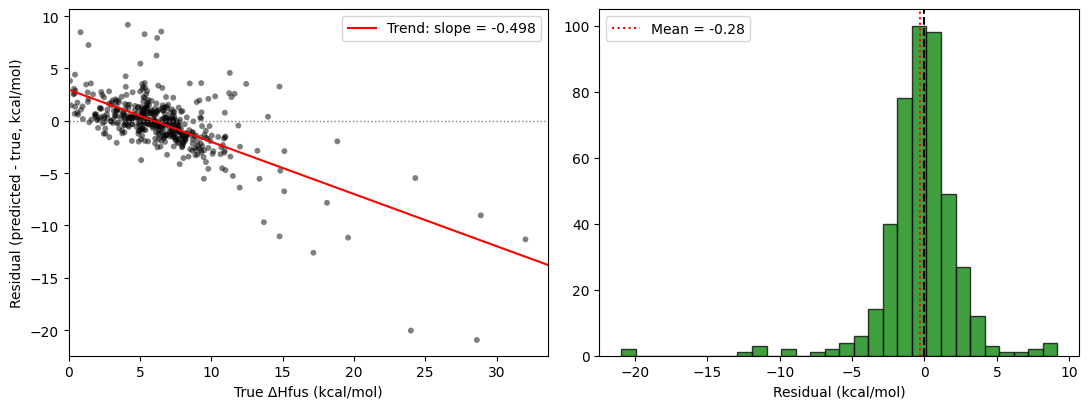

In [7]:
#RESIDUALS: IS THERE A BIAS WITH THE TRUE VALUE (REGRESSION TO THE MEAN)?
slope, intercept = np.polyfit(pred["y_true"], pred["residual"], 1)          #NEGATIVE SLOPE = UNDERPREDICTS HIGH VALUES, OVERPREDICTS LOW VALUES
corr = np.corrcoef(pred["y_true"], pred["residual"])[0, 1]
print(f"RESIDUAL TREND SLOPE: {slope:.3f} | CORRELATION BETWEEN TRUE VALUE AND RESIDUAL: {corr:.3f} | MEAN RESIDUAL: {pred['residual'].mean():.3f} | SD: {pred['residual'].std():.3f}")
tert = pd.qcut(pred["y_true"], 3, labels=["Low third", "Middle third", "High third"])
print(pred.groupby(tert, observed=True)["residual"].agg(["count", "mean"]).round(3))   #MEAN RESIDUAL PER THIRD OF THE TRUE VALUES
print(pred.groupby(tert, observed=True)["abs_error"].mean().round(3).rename("MAE per third"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(pred["y_true"], pred["residual"], alpha=0.5, s=18, color="black", edgecolor="none")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=1)
tx = np.array([0, pred["y_true"].max() * 1.05])
axes[0].plot(tx, slope * tx + intercept, color="red", linewidth=1.5, label=f"Trend: slope = {slope:.3f}")
axes[0].set_xlim(0, tx[1]); axes[0].set_xlabel(f"True {NAME} ({UNIT})"); axes[0].set_ylabel(f"Residual (predicted - true, {UNIT})"); axes[0].legend()
axes[1].hist(pred["residual"], bins=30, edgecolor="black", alpha=0.75, color="green")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(pred["residual"].mean(), color="red", linestyle=":", label=f"Mean = {pred['residual'].mean():.2f}")
axes[1].set_xlabel(f"Residual ({UNIT})"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"plots_{DS}_residuals.png", dpi=150); plt.show()

                   n    mae  median_ae  mean_residual
functional_class                                     
Carboxylic acid   27  2.762      1.238          0.130
Ether             62  2.555      1.413         -0.540
Amine             93  1.798      1.541         -0.741
Alkane/Other      67  1.563      1.158          0.172
Alcohol           24  1.496      1.241          0.371
Aromatic          98  1.399      0.972         -0.256
Alkene            11  1.252      1.057         -0.536
Ester             60  1.216      1.090         -0.338
Amide              8  0.513      0.276          0.299

PER-CLASS RESIDUAL TREND SLOPE:
  Alcohol          n=  24  slope=-0.336
  Alkane/Other     n=  67  slope=-0.153
  Alkene           n=  11  slope=-0.461
  Amide            n=   8  slope=-0.023
  Amine            n=  93  slope=-0.734
  Aromatic         n=  98  slope=-0.710
  Carboxylic acid  n=  27  slope=-0.901
  Ester            n=  60  slope=-0.476
  Ether            n=  62  slope=-0.440


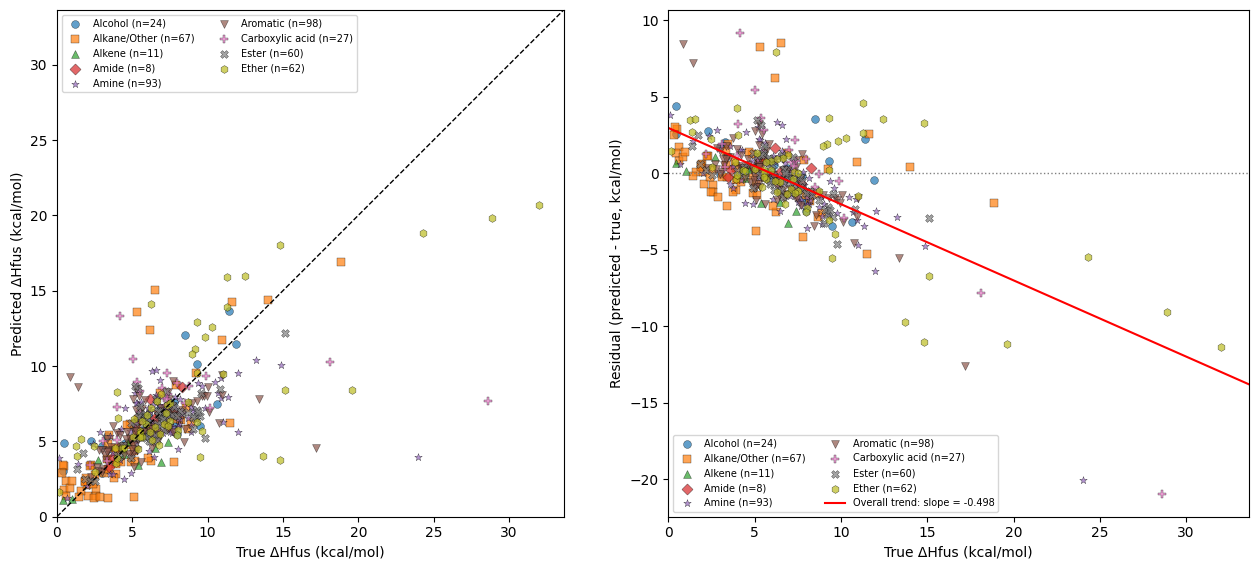

In [8]:
#FUNCTIONAL GROUP CLASSES (EACH MOLECULE GETS THE FIRST MATCHING CLASS IN THIS ORDER, SO CLASSES DO NOT OVERLAP)
FUNCTIONAL_GROUPS = {
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[#6][CX3](=O)[OX2H0][#6]",
    "Amide": "[CX3](=[OX1])[NX3]",
    "Amine": "[NX3;H2,H1,H0;!$(NC=O)]",
    "Alcohol": "[OX2H][CX4]",
    "Ether": "[OD2]([#6])[#6]",
    "Aromatic": "c1ccccc1",
    "Alkene": "[CX3]=[CX3]",
    "Alkyne": "[CX2]#[CX2]",
}
PATTERNS = {k: Chem.MolFromSmarts(v) for k, v in FUNCTIONAL_GROUPS.items()}   #COMPILED ONCE

def classify_molecule(smi):                                                #FIRST MATCHING CLASS, "Alkane/Other" IF NONE MATCH
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return "Unknown"
    for name, patt in PATTERNS.items():
        if mol.HasSubstructMatch(patt):
            return name
    return "Alkane/Other"

pred["functional_class"] = pred["smiles"].apply(classify_molecule)
cls_tab = pred.groupby("functional_class").agg(n=("abs_error", "count"), mae=("abs_error", "mean"), median_ae=("abs_error", "median"),
                                               mean_residual=("residual", "mean")).sort_values("mae", ascending=False).round(3)
print(cls_tab)                                                             #CLASSES WITH VERY FEW MOLECULES (n < 10) SHOULD NOT BE INTERPRETED
print("\nPER-CLASS RESIDUAL TREND SLOPE:")
classes = sorted(pred["functional_class"].unique())
for c in classes:
    sub = pred[pred["functional_class"] == c]
    if len(sub) >= 5:
        print(f"  {c:16s} n={len(sub):4d}  slope={np.polyfit(sub['y_true'], sub['residual'], 1)[0]:+.3f}")
    else:
        print(f"  {c:16s} n={len(sub):4d}  (TOO FEW POINTS FOR A TREND)")

MARKERS = ["o", "s", "^", "D", "*", "v", "P", "X", "h", "<", ">"]          #AT LEAST ONE MARKER PER CLASS (THE OLD LIST DROPPED THE LAST CLASS)
COLOURS = plt.cm.tab10(np.linspace(0, 1, 10))
lim = max(pred["y_true"].max(), pred["y_pred"].max()) * 1.05
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for i, c in enumerate(classes):
    sub = pred[pred["functional_class"] == c]
    kw = dict(alpha=0.7, s=32, color=COLOURS[i % 10], marker=MARKERS[i % len(MARKERS)], edgecolor="black", linewidth=0.3, label=f"{c} (n={len(sub)})")
    axes[0].scatter(sub["y_true"], sub["y_pred"], **kw)
    axes[1].scatter(sub["y_true"], sub["residual"], **kw)
axes[0].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim); axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel(f"True {NAME} ({UNIT})"); axes[0].set_ylabel(f"Predicted {NAME} ({UNIT})")
axes[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[1].plot(tx, slope * tx + intercept, color="red", linewidth=1.5, label=f"Overall trend: slope = {slope:.3f}")
axes[1].set_xlim(0, tx[1]); axes[1].set_xlabel(f"True {NAME} ({UNIT})"); axes[1].set_ylabel(f"Residual (predicted - true, {UNIT})")
axes[0].legend(loc="upper left", fontsize=7, ncol=2); axes[1].legend(loc="lower left", fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"plots_{DS}_by_class.png", dpi=150); plt.show()

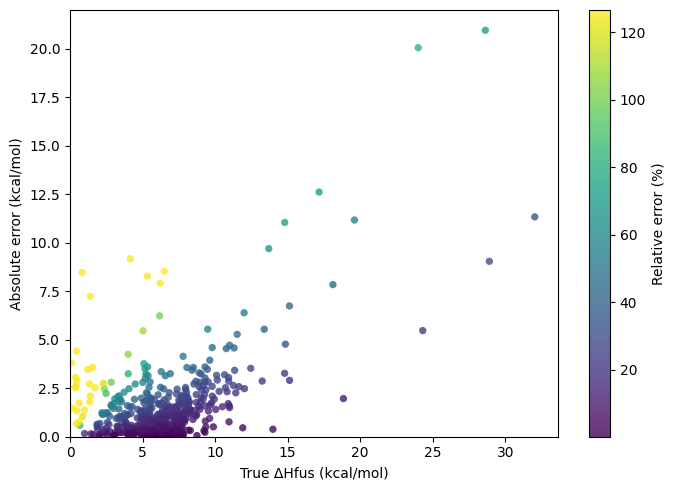

In [9]:
#ABSOLUTE ERROR VS TRUE VALUE, COLOURED BY RELATIVE ERROR
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pred["y_true"], pred["abs_error"], c=pred["rel_error_pct"], cmap="viridis", s=28, alpha=0.8, edgecolor="none",
                vmax=pred["rel_error_pct"].quantile(0.95))                 #COLOUR SCALE CAPPED AT THE 95TH PERCENTILE
plt.colorbar(sc, ax=ax).set_label("Relative error (%)")
ax.set_xlim(0, pred["y_true"].max() * 1.05); ax.set_ylim(0, pred["abs_error"].max() * 1.05)
ax.set_xlabel(f"True {NAME} ({UNIT})"); ax.set_ylabel(f"Absolute error ({UNIT})")
plt.tight_layout(); plt.savefig(f"plots_{DS}_error_bubble.png", dpi=150); plt.show()

In [ ]:
#ALL NUMBERS NEEDED FOR THE BASELINE SECTION OF THE REPORT
b1, b2 = CFG["bands"]
report = {
    "10-seed test MAE mean": seeds["test_mae"].mean(), "10-seed test MAE SD": seeds["test_mae"].std(),
    "10-seed test RMSE mean": seeds["test_rmse"].mean(), "10-seed test RMSE SD": seeds["test_rmse"].std(),
    "seed 0 test MAE": mae, "seed 0 test RMSE": rmse,
    "seed 0 median abs error": pred["abs_error"].median(),
    f"seed 0 % within {b1:g}": 100 * (pred["abs_error"] <= b1).mean(),
    f"seed 0 % within {b2:g}": 100 * (pred["abs_error"] <= b2).mean(),
    "seed 0 median relative error %": rel.median(),
    "seed 0 residual slope": slope, "seed 0 residual correlation": corr, "seed 0 mean residual": pred["residual"].mean(),
}
report = pd.Series(report).round(3)
print(report.to_string())
report.to_csv(f"{DS}_baseline_report_numbers.csv", header=["value"])


10-seed test MAE mean              1.816
10-seed test MAE SD                0.139
10-seed test RMSE mean             3.359
10-seed test RMSE SD               1.037
seed 0 test MAE                    1.708
seed 0 test RMSE                   2.788
seed 0 median abs error            1.154
seed 0 % within 1.5               61.556
seed 0 % within 3                 86.667
seed 0 median relative error %    18.485
seed 0 residual slope             -0.498
seed 0 residual correlation       -0.672
seed 0 mean residual              -0.283


In [ ]:
# SHARE OF MULTI-COMPONENT SMILES (SALTS, MIXTURES) IN EACH CLEAN DATASET AND ITS SEED 0 TEST SET
for ds, f in [("dHfus", "RAW DATA/dHfus_clean.csv"), ("Tm", "RAW DATA/Tm_clean.csv")]:
    c = pd.read_csv(f)
    p = pd.read_csv(f"{ds}_baseline_predictions.csv")
    print(ds, "| WHOLE DATASET:", round(c["smiles"].str.contains(r"\.").mean() * 100, 1), "% | SEED 0 TEST SET:", round(p["smiles"].str.contains(r"\.").mean() * 100, 1), "%")
    print("   MAE WITH '.':", round(p.loc[p["smiles"].str.contains(r"\."), "abs_error"].mean(), 2), "| WITHOUT:", round(p.loc[~p["smiles"].str.contains(r"\."), "abs_error"].mean(), 2))
    

dHfus | WHOLE DATASET: 8.1 % | SEED 0 TEST SET: 11.8 %
   MAE WITH '.': 1.83 | WITHOUT: 1.69
Tm | WHOLE DATASET: 0.6 % | SEED 0 TEST SET: 0.4 %
   MAE WITH '.': 38.8 | WITHOUT: 32.01


In [12]:
import chemprop                                                                  #IMPORTS CHEMPROP TO READ ITS VERSION
from chemprop import nn, models                                                  #IMPORTS THE MODEL BUILDING BLOCKS

mp = nn.BondMessagePassing(dropout=0.2)                                          #SAME CALL AS IN build_and_train_mpnn
agg = nn.MeanAggregation()
ffn = nn.RegressionFFN(dropout=0.2)
mpnn = models.MPNN(mp, agg, ffn, True, [nn.metrics.RMSE(), nn.metrics.MAE()])    #TRUE = BATCH NORM, AS IN YOUR FUNCTION

print("Chemprop version:", chemprop.__version__)
print(mpnn)                                                                      #FULL ARCHITECTURE, INCLUDING LAYER SIZES
print("Message passing depth:", mp.depth, "| hidden size:", mp.output_dim)
print("Optimizer settings:", mpnn.warmup_epochs, mpnn.init_lr, mpnn.max_lr, mpnn.final_lr)

Chemprop version: 2.2.3
MPNN(
  (message_passing): BondMessagePassing(
    (W_i): Linear(in_features=86, out_features=300, bias=False)
    (W_h): Linear(in_features=300, out_features=300, bias=False)
    (W_o): Linear(in_features=372, out_features=300, bias=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (tau): ReLU()
    (V_d_transform): Identity()
    (graph_transform): Identity()
  )
  (agg): MeanAggregation()
  (bn): BatchNorm1d(300, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (predictor): RegressionFFN(
    (ffn): MLP(
      (0): Sequential(
        (0): Linear(in_features=300, out_features=300, bias=True)
      )
      (1): Sequential(
        (0): ReLU()
        (1): Dropout(p=0.2, inplace=False)
        (2): Linear(in_features=300, out_features=1, bias=True)
      )
    )
    (criterion): MSE(task_weights=[[1.0]])
    (output_transform): Identity()
  )
  (X_d_transform): Identity()
  (metrics): ModuleList(
    (0): RMSE(task_weights=[[1.0]])
    (1)